# Student Performance Data Analysis

## 1. Dataset Loading and Initial Exploration

This project analyzes student academic performance
using descriptive statistics and linear regression.

Dataset: Student Performance (UCI Machine Learning Repository).

In [1]:
import pandas as pd

df = pd.read_csv("data/student-mat.csv", sep=";")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



## 2. Research Question and Hypotheses

### Research Question

Is there a statistically significant relationship between students' previous grades (G1 and G2) and their final grade (G3)?

### Variables

- **G1:** First period grade (Independent Variable)
- **G2:** Second period grade (Independent Variable)
- **G3:** Final grade (Dependent Variable)

### Hypotheses

**H0 (Null Hypothesis):**
The regression coefficients of G1 and G2 are both equal to zero.

**H1 (Alternative Hypothesis):**
At least one of the regression coefficients is different from zero.

**Significance Level:** alpha = 0.05

## 3. Stevens Measurement Scale Classification

Each variable is classified according to Stevens' four measurement scales:

- **Nominal:** Categories without a natural order.
- **Ordinal:** Categories with a meaningful order.
- **Interval:** Numerical values with meaningful differences.
- **Ratio:** Numerical values with a meaningful absolute zero.


In [2]:
stevens = {
    "Nominal": [
        "school", "sex", "address", "Pstatus",
        "Mjob", "Fjob", "reason", "guardian",
        "schoolsup", "famsup", "paid", "activities",
        "nursery", "higher", "internet", "romantic"
    ],

    "Ordinal": [
        "famsize", "Medu", "Fedu", "traveltime",
        "studytime", "failures", "famrel",
        "freetime", "goout", "Dalc", "Walc", "health"
    ],

    "Interval": [
        "G1", "G2", "G3"
    ],

    "Ratio": [
        "age", "absences"
    ]
}

classification = {
    column: scale
    for scale, columns in stevens.items()
    for column in columns
}

classification_table = pd.DataFrame({
    "Variable": df.columns,
    "Python Data Type": df.dtypes.astype(str).values,
    "Stevens Scale": [
        classification.get(col, "Unclassified")
        for col in df.columns
    ]
})

display(classification_table)

print("\nVariables by measurement scale:")
print(classification_table["Stevens Scale"].value_counts())

assert set(df.columns) == set(classification)

print("\nAll 33 variables have been classified!")


,Variable,Python Data Type,Stevens Scale
0,school,str,Nominal
1,sex,str,Nominal
2,age,int64,Ratio
3,address,str,Nominal
4,famsize,str,Ordinal
5,Pstatus,str,Nominal
6,Medu,int64,Ordinal
7,Fedu,int64,Ordinal
8,Mjob,str,Nominal
9,Fjob,str,Nominal



Variables by measurement scale:
Stevens Scale
Nominal     16
Ordinal     12
Interval     3
Ratio        2
Name: count, dtype: int64

All 33 variables have been classified!



## 4. Data Cleaning and Outlier Detection

This section evaluates the quality of the dataset.

The following checks are performed:

- Missing values
- Duplicate records
- Outlier detection using the IQR method

### Outlier Detection

The Interquartile Range (IQR) method is used:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR

Upper Bound = Q3 + 1.5 * IQR

Outliers are reviewed before deciding whether to remove them.

The dataset contains valid extreme observations.
Therefore, all 395 records are retained for analysis.


In [3]:

print("=== MISSING VALUES ===")
print("Total missing values:", df.isnull().sum().sum())

print("\n=== DUPLICATES ===")
print("Total duplicates:", df.duplicated().sum())

print("\n=== OUTLIER DETECTION ===")

numeric_columns = ["age", "absences", "G1", "G2", "G3"]

outliers_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outliers_summary.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": len(outliers)
    })

outliers_df = pd.DataFrame(outliers_summary)
display(outliers_df)

df_clean = df.copy()

print("\n=== FINAL DATASET ===")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Data unchanged:", df.equals(df_clean))


=== MISSING VALUES ===
Total missing values: 0

=== DUPLICATES ===
Total duplicates: 0

=== OUTLIER DETECTION ===


,Variable,Lower Bound,Upper Bound,Outliers
0,age,13.0,21.0,1
1,absences,-12.0,20.0,15
2,G1,0.5,20.5,0
3,G2,3.0,19.0,13
4,G3,-1.0,23.0,0



=== FINAL DATASET ===
Original shape: (395, 33)
Cleaned shape: (395, 33)
Data unchanged: True



## 5. Descriptive Statistics and Data Visualization

This section explores the statistical characteristics of student academic performance.

The analysis includes:

- Mean, median, and standard deviation
- Minimum and maximum values
- Variance and quartiles
- Histogram of final grades (G3)
- Scatter plot of G2 and G3
- Boxplot comparing G1, G2, and G3

The objective is to understand the distribution of grades, identify patterns, and explore potential relationships between variables.


In [4]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["age", "absences", "G1", "G2", "G3"]

statistics = df_clean[columns].describe().T

statistics["median"] = df_clean[columns].median()
statistics["variance"] = df_clean[columns].var()

print("=== DESCRIPTIVE STATISTICS ===")
display(statistics.round(2))


=== DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max,median,variance
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0,17.0,1.63
absences,395.0,5.71,8.00,0.0,0.0,4.0,8.0,75.0,4.0,64.05
G1,395.0,10.91,3.32,3.0,8.0,11.0,13.0,19.0,11.0,11.02
G2,395.0,10.71,3.76,0.0,9.0,11.0,13.0,19.0,11.0,14.15
G3,395.0,10.42,4.58,0.0,8.0,11.0,14.0,20.0,11.0,20.99


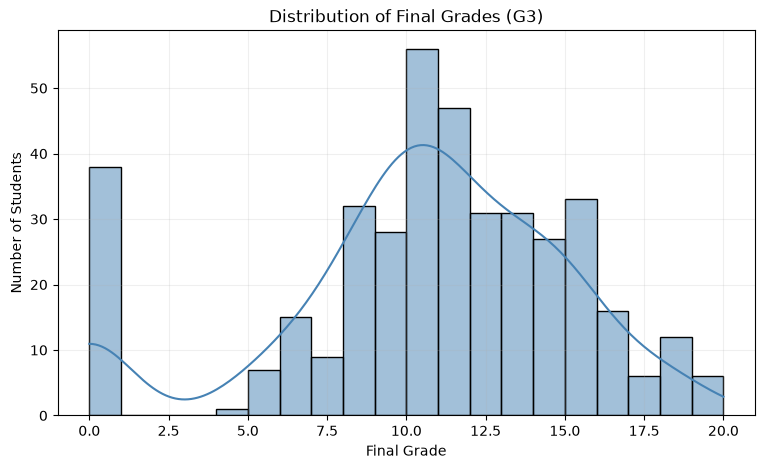

In [5]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="G3",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.grid(alpha=0.2)

plt.show()


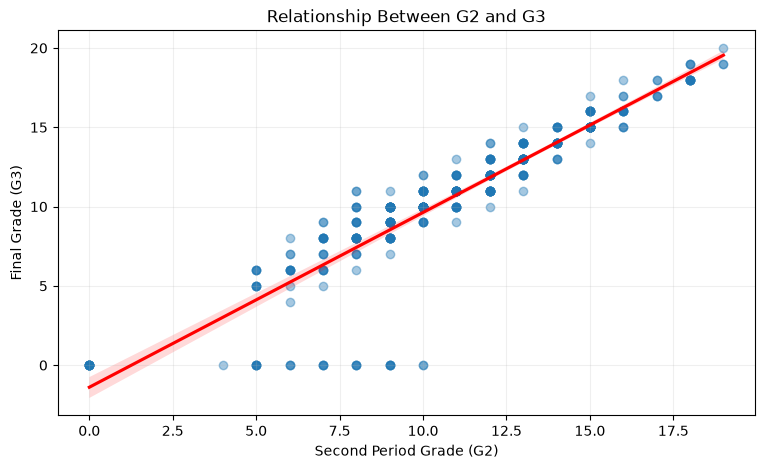

In [6]:

plt.figure(figsize=(9, 5))

sns.regplot(
    data=df_clean,
    x="G2",
    y="G3",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Relationship Between G2 and G3")
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.grid(alpha=0.2)

plt.show()


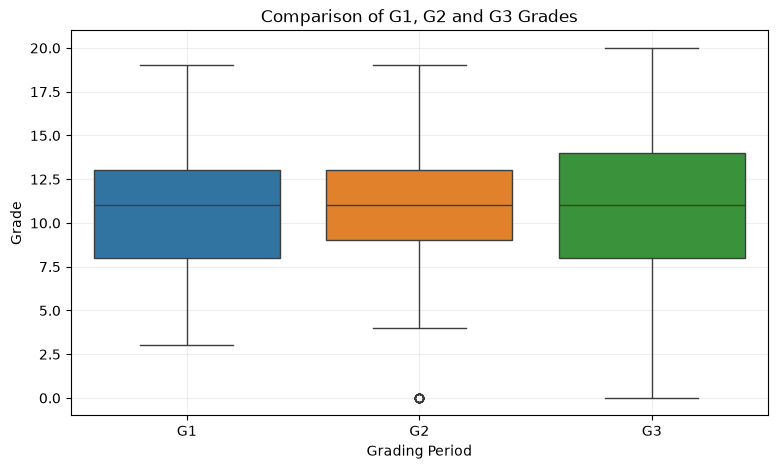

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean[["G1", "G2", "G3"]]
)

plt.title("Comparison of G1, G2 and G3 Grades")
plt.xlabel("Grading Period")
plt.ylabel("Grade")
plt.grid(alpha=0.2)

plt.show()



### Interpretation of Descriptive Statistics

The dataset contains 395 student records.

The average student age is 16.70 years, while the average number of absences is 5.71.

The average grades are:

- G1: 10.91
- G2: 10.71
- G3: 10.42

The results indicate a slight decrease in average grades from the first grading period to the final grade.

G3 has the highest standard deviation (4.58), indicating greater variability in final grades.

The scatter plot suggests a positive linear relationship between G2 and G3.

The boxplot allows comparison of grade distributions and identification of potential outliers.

These findings provide the foundation for correlation analysis and linear regression modeling.
